# Quantum annealing from the longitudinal gadget Hamiltonian

Protocol (same spirit as the He6 notebook, but with no separate driver):

$$H(t) = H_Z + s(t)\,H_X, \qquad s(t) = t/\tau,$$

where $H_Z$ is the longitudinal part of the gadget (one-hot / particle-number constraints,
$\epsilon_A$, $g^{(2)}_{AB}$ and the self-energy compensation) and $H_X = \sum_A \tfrac{d_A}{\sqrt 2} X_A$
are the drivings, switched on linearly until the full gadget $H_G = H_Z + H_X$.
The initial state is the **classical ground state of $H_Z$** (a localized bitstring).

Along the sweep we record the lowest instantaneous levels $e_i(t)$ and the populations
$p_i(t) = |\langle \phi_i(t)|\psi(t)\rangle|^2$; the levels are coloured by $p_i(t)$, so a
non-adiabatic transfer shows up directly as colour moving from the ground level to an excited one.
The dashed line is $e(t) = \langle\psi(t)|H(t)|\psi(t)\rangle$.

* **Particle conservation** ($D$ qubits, $c_{AB}=0$): O20 ($N=2$), three annealing times $\tau$.
  For $N=1$ the two encodings coincide, so $N=2$ is the first case where the encoding matters.
* **First quantization** ($N\times D$ qubits, $c_{AB}\in\,]-1,4]$): O18 (6 qubits), O20 (12), Ca42 (10).
  $H(t)$ commutes with the exchange of registers, and the classical minimum of $H_Z$ is $N!$-fold degenerate:
  the initial state is the **symmetric (bosonic)** combination.  Levels are computed sector by sector, so
  bosonic (symmetric) and fermionic (antisymmetric, unphysical) levels are drawn differently.

Energies are shown as $e_i\,\gamma$ (the logical sector lives at $E/\gamma$); time is in gadget units.
Figures are saved in `figures/annealing_hz/`, the raw curves in `data/annealing_hz/`.


In [1]:
import os, time, warnings
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D

from src.gadget import (
    FirstQuantizationEncoding,
    GadgetHamiltonian,
    GadgetParameters,
    ParticleConservationEncoding,
    QuasiparticleProblem,
    fit_drive,
    fit_drive_bounded,
)
from src.gadget.hz_annealing import hz_anneal, minimum_gap

warnings.filterwarnings("ignore")
DATA = "data/matrix_elements_h_eff_2body"
FIGDIR, OUTDIR = "figures/annealing_hz", "data/annealing_hz"
os.makedirs(FIGDIR, exist_ok=True)
os.makedirs(OUTDIR, exist_ok=True)

NUCLEI = {"O18": ("sd", 1), "O20": ("sd", 2), "O22": ("sd", 3), "Ca42": ("pf", 1), "Ca44": ("pf", 2)}


def problem(label):
    shell, N = NUCLEI[label]
    D = {"sd": 6, "pf": 10}[shell]
    return QuasiparticleProblem.from_npz(
        f"{DATA}/one_body_nn_{shell}.npz",
        f"{DATA}/twobody_nn_{shell}.npz" if N > 1 else None,
        n_levels=D, n_particles=N, label=label,
    )


def gadget(label, encoding, gamma, c_max=4.0, seed=42):
    '''GadgetHamiltonian of `label` in encoding 'pc' or 'fq'.

    pc: rank-1 drive (c_AB = 0, the convention of the gamma scan);
    fq: bounded fit with c_AB in ]-1, c_max].'''
    p = problem(label)
    if encoding == "pc":
        drive = fit_drive(p.g1, n_restarts=30, use_c=False, seed=seed)
        enc = ParticleConservationEncoding(p)
    else:
        drive = fit_drive_bounded(p.g1, c_max=c_max, seed=seed)
        enc = FirstQuantizationEncoding(p)
    return GadgetHamiltonian(p, enc, drive, GadgetParameters(gamma=gamma))


## Plotting

One row of three wide panels (full-page-width figure).  Each level is a line coloured by its
population; the colour bar on the right is shared.  Fermionic (antisymmetric) levels, when present,
are dotted grey.  No titles, only (a) (b) (c).

In [2]:
POP_CMAP = LinearSegmentedColormap.from_list("pop", ["#d0d0d0", "#f4a259", "#c1121f", "#5a0a10"])
POP_NORM = Normalize(0.0, 1.0)


def draw_levels(ax, r, n_show=None, lw=2.2):
    '''Levels of one HZAnnealResult on `ax`, coloured by population.'''
    t, g = r.times, r.gamma
    keep = [i for i, sec in enumerate(r.sector) if sec != "A"]
    if n_show is not None:
        keep = keep[:n_show]
    for i in keep:
        y = r.levels[:, i] * g
        pts = np.column_stack([t, y]).reshape(-1, 1, 2)
        segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
        lc = LineCollection(segs, cmap=POP_CMAP, norm=POP_NORM, linewidths=lw, zorder=2)
        lc.set_array(0.5 * (r.populations[:-1, i] + r.populations[1:, i]))
        ax.add_collection(lc)
    ferm = [i for i, sec in enumerate(r.sector) if sec == "A"]
    for i in ferm:
        ax.plot(t, r.levels[:, i] * g, ls=":", lw=1.3, color="#3a6ea5", zorder=1)
    ax.plot(t, r.energy * g, "k--", lw=1.3, zorder=3)
    ax.set_xlim(t[0], t[-1])
    ys = np.concatenate([r.levels[:, keep].ravel() * g, r.energy * g])  # fermionic levels may be clipped
    pad = 0.06 * (ys.max() - ys.min())
    ax.set_ylim(ys.min() - pad, ys.max() + pad)
    return lc


def plot_row(results, path, texts, n_show=5, ylabel=r"$e_i\,\gamma$ [MeV]"):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    for k, (ax, r, txt) in enumerate(zip(axes, results, texts)):
        lc = draw_levels(ax, r, n_show=n_show)
        ax.set_title(f"({'abc'[k]})", loc="left", fontweight="bold", fontsize=13)
        ax.set_xlabel(r"$t$", fontsize=13)
        ax.text(0.03, 0.04, txt, transform=ax.transAxes, fontsize=12, va="bottom",
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.7", alpha=0.9))
        ax.grid(alpha=0.25)
        ax.tick_params(labelsize=11)
    axes[0].set_ylabel(ylabel, fontsize=13)
    handles = [Line2D([], [], color="#c1121f", lw=2.2, label="levels $e_i(t)$ (colour = population)"),
               Line2D([], [], color="k", ls="--", lw=1.3, label=r"$e(t)=\langle H(t)\rangle$")]
    if any((r.sector == "A").any() for r in results):
        handles.insert(1, Line2D([], [], color="#3a6ea5", ls=":", lw=1.3, label="fermionic (antisymmetric) levels"))
        handles[0].set_label("bosonic (symmetric) levels, colour = population")
    axes[0].legend(handles=handles, fontsize=9, loc="upper right", framealpha=0.9)
    fig.subplots_adjust(left=0.05, right=0.93, bottom=0.14, top=0.92, wspace=0.18)
    cax = fig.add_axes([0.945, 0.14, 0.012, 0.78])
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=POP_NORM, cmap=POP_CMAP), cax=cax)
    cb.set_label(r"population $|\langle\phi_i(t)|\psi(t)\rangle|^2$", fontsize=11)
    fig.savefig(path + ".pdf")
    fig.savefig(path + ".png", dpi=200)
    print("->", path + ".pdf")
    return fig


## Parameters

Every quantity in gadget units; `GAMMA` sets the constraint strength.  The logical gaps scale as
$1/\gamma$, so the adiabatic time scales as $\gamma^2$.

`MAX_FLIPS` restricts the dynamics to the computational states within that many bit flips of the
code space.  The weight on a $k$-flip state is $O((d/\gamma)^k)$, so 3 flips is exact to $\sim 10^{-8}$,
while the spectral width (which sets the cost of the propagator) drops from $\sim D^2\gamma$ to $\sim 9\gamma$.

In [3]:
GAMMA = 20.0
TAUS_PC = [30.0, 300.0, 3000.0]        # particle conservation: diabatic -> adiabatic
TAU_FQ = 3000.0                        # first quantization, one annealing time
NUCLEUS_PC = "O20"
NUCLEI_FQ = ["O18", "O20", "Ca42"]
N_LEVELS = 6                           # instantaneous levels tracked (per sector)
N_RECORD = 200
MAX_FLIPS = 3                          # dynamics restricted to <= 3 constraint violations
                                       # (amplitude O((d/gamma)^3) beyond; None = full space)


## Particle conservation: O20, three annealing times

In [4]:
H_pc = gadget(NUCLEUS_PC, "pc", GAMMA)
s_min, gap_min, _, _ = minimum_gap(H_pc, 41, max_flips=MAX_FLIPS)
print(f"{NUCLEUS_PC} pc, gamma={GAMMA}: {H_pc.n_qubits} qubits, minimum gap {gap_min:.4f} at s={s_min:.2f}  "
      f"(gap*gamma={gap_min*GAMMA:.3f} MeV)")

results_pc = []
for tau in TAUS_PC:
    t0 = time.time()
    r = hz_anneal(H_pc, tau, n_record=N_RECORD, n_levels=N_LEVELS, max_flips=MAX_FLIPS)
    r.save(f"{OUTDIR}/{NUCLEUS_PC}_pc_gamma{GAMMA:g}_tau{tau:g}.npz")
    results_pc.append(r)
    print(f"  tau={tau:7g}: F(exact)={r.fidelity_exact:.4f}  F(gadget gs)={r.fidelity_gadget:.4f}  "
          f"leakage={r.leakage:.4f}  E_final*gamma={r.energy[-1]*GAMMA:.3f}  "
          f"(gadget {r.gadget_energy*GAMMA:.3f}, exact {r.exact_energy:.3f})  [{time.time()-t0:.0f}s]")


O20 pc, gamma=20.0: 6 qubits, minimum gap 0.0085 at s=0.00  (gap*gamma=0.170 MeV)


  tau=     30: F(exact)=0.3654  F(gadget gs)=0.3668  leakage=0.0117  E_final*gamma=-21.062  (gadget -23.410, exact -23.425)  [4s]


  tau=    300: F(exact)=0.6686  F(gadget gs)=0.6672  leakage=0.0150  E_final*gamma=-22.218  (gadget -23.410, exact -23.425)  [6s]


  tau=   3000: F(exact)=0.9763  F(gadget gs)=0.9998  leakage=0.0183  E_final*gamma=-23.409  (gadget -23.410, exact -23.425)  [59s]


-> figures/annealing_hz/annealing_hz_pc_O20.pdf


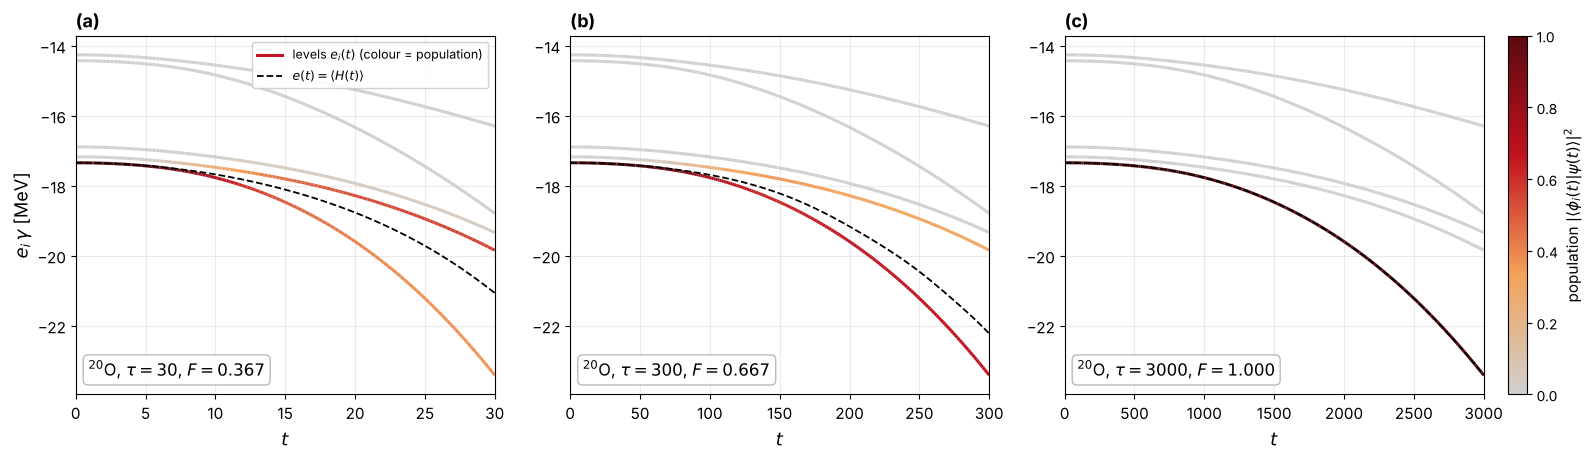

In [5]:
texts = [rf"$^{{20}}$O, $\tau={r.tau:g}$, $F={r.fidelity_gadget:.3f}$" for r in results_pc]
fig = plot_row(results_pc, f"{FIGDIR}/annealing_hz_pc_{NUCLEUS_PC}", texts)
plt.show()


## First quantization: O18, O20, Ca42

The initial state is the symmetric combination of the $N!$ degenerate classical minima of $H_Z$.
For O20 ($N=2$) the antisymmetric (fermionic) levels are drawn dotted: they are never populated,
since $H(t)$ commutes with the register exchange.

In [6]:
results_fq = []
for label in NUCLEI_FQ:
    H = gadget(label, "fq", GAMMA)
    s_min, gap_min, _, _ = minimum_gap(H, 21, max_flips=MAX_FLIPS)
    t0 = time.time()
    r = hz_anneal(H, TAU_FQ, n_record=N_RECORD, n_levels=N_LEVELS, max_flips=MAX_FLIPS)
    r.save(f"{OUTDIR}/{label}_fq_gamma{GAMMA:g}_tau{TAU_FQ:g}.npz")
    results_fq.append(r)
    print(f"{label} fq ({H.n_qubits} qubits): min gap {gap_min:.4f} at s={s_min:.2f};  tau={TAU_FQ:g}: "
          f"F(exact)={r.fidelity_exact:.4f}  F(gadget gs)={r.fidelity_gadget:.4f}  leakage={r.leakage:.4f}  "
          f"E_final*gamma={r.energy[-1]*GAMMA:.3f} (gadget {r.gadget_energy*GAMMA:.3f}, exact {r.exact_energy:.3f})  "
          f"[{time.time()-t0:.0f}s]")


O18 fq (6 qubits): min gap 0.0176 at s=0.30;  tau=3000: F(exact)=0.9676  F(gadget gs)=1.0000  leakage=0.0319  E_final*gamma=-11.674 (gadget -11.674, exact -11.932)  [94s]


O20 fq (12 qubits): min gap 0.0382 at s=0.40;  tau=3000: F(exact)=0.9456  F(gadget gs)=1.0000  leakage=0.0542  E_final*gamma=-23.048 (gadget -23.048, exact -23.425)  [424s]


Ca42 fq (10 qubits): min gap 0.0015 at s=0.00;  tau=3000: F(exact)=0.8288  F(gadget gs)=0.8702  leakage=0.0362  E_final*gamma=-19.765 (gadget -19.970, exact -19.734)  [135s]


-> figures/annealing_hz/annealing_hz_fq_O18_O20_Ca42.pdf


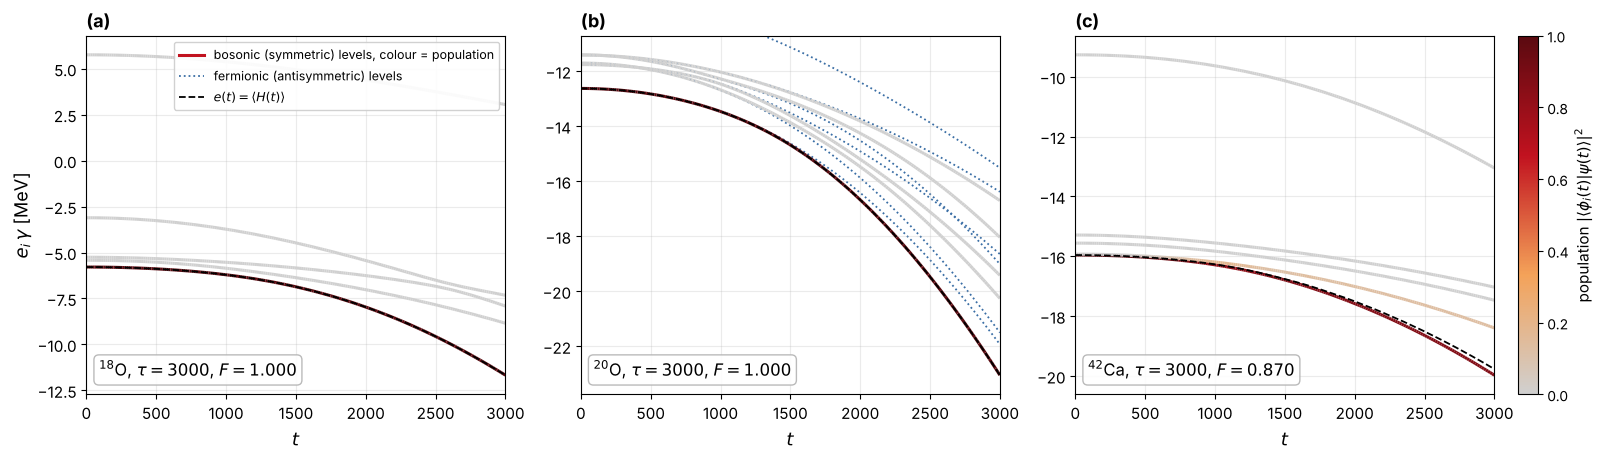

In [7]:
PRETTY = {"O18": r"$^{18}$O", "O20": r"$^{20}$O", "O22": r"$^{22}$O", "Ca42": r"$^{42}$Ca", "Ca44": r"$^{44}$Ca"}
texts = [rf"{PRETTY[r.label]}, $\tau={r.tau:g}$, $F={r.fidelity_gadget:.3f}$" for r in results_fq]
fig = plot_row(results_fq, f"{FIGDIR}/annealing_hz_fq_" + "_".join(NUCLEI_FQ), texts)
plt.show()


## Summary

In [8]:
print(f"{'case':22s} {'qubits':>6s} {'tau':>7s} {'F(gadget gs)':>13s} {'F(exact)':>9s} {'leakage':>8s} {'E_final*g':>10s} {'E_exact':>8s}")
for r, H in [(r, H_pc) for r in results_pc] + list(zip(results_fq, [gadget(l, "fq", GAMMA) for l in NUCLEI_FQ])):
    print(f"{r.label + ' ' + r.encoding:22s} {H.n_qubits:6d} {r.tau:7g} {r.fidelity_gadget:13.4f} {r.fidelity_exact:9.4f} "
          f"{r.leakage:8.4f} {r.energy[-1]*r.gamma:10.3f} {r.exact_energy:8.3f}")


case                   qubits     tau  F(gadget gs)  F(exact)  leakage  E_final*g  E_exact


O20 pc                      6      30        0.3668    0.3654   0.0117    -21.062  -23.425
O20 pc                      6     300        0.6672    0.6686   0.0150    -22.218  -23.425
O20 pc                      6    3000        0.9998    0.9763   0.0183    -23.409  -23.425
O18 fq                      6    3000        1.0000    0.9676   0.0319    -11.674  -11.932
O20 fq                     12    3000        1.0000    0.9456   0.0542    -23.048  -23.425
Ca42 fq                    10    3000        0.8702    0.8288   0.0362    -19.765  -19.734
